# Exploratory Data Analysis

This notebook explores the final modelling dataset used for UK GDP nowcasting. The analysis focuses on GDP growth dynamics, the behaviour of key macroeconomic predictors, correlation structure, major economic shocks, and the evolution of information availability across the M1, M2 and M3 nowcasting sets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
model_dataset = pd.read_csv(
    "../data/processed/model_dataset.csv"
)

model_dataset.head()

,quarter,gdp_qoq,gdp_monthly_m1,gdp_monthly_m2,gdp_monthly_m3,services_m1,services_m2,services_m3,industrial_production_m1,industrial_production_m2,...,cpi_inflation_m3,bank_rate_m1,bank_rate_m2,bank_rate_m3,consumer_confidence_m1,consumer_confidence_m2,consumer_confidence_m3,oecd_cli_m1,oecd_cli_m2,oecd_cli_m3
0,2006Q1,0.4,-0.4,-0.1,0.4,-0.2,-0.2,0.2,-1.5,0.1,...,1.8,4.50,4.50,4.50,-3.0,-4.0,-7.0,100.5471,100.7167,100.8848
1,2006Q2,0.3,-0.4,0.5,0.2,-0.5,0.4,0.1,-0.1,1.0,...,2.5,4.50,4.50,4.50,-4.0,-5.0,-4.0,101.0458,101.1928,101.3334
2,2006Q3,0.2,-0.5,0.3,0.3,-0.5,0.3,0.3,-1.0,0.7,...,2.4,4.50,4.75,4.75,-4.0,-8.0,-7.0,101.4845,101.6628,101.8751
3,2006Q4,0.4,-0.6,0.5,0.9,-0.5,0.4,1.2,-1.3,0.8,...,3.0,4.75,5.00,5.00,-5.0,-7.0,-8.0,102.1039,102.3324,102.5540
4,2007Q1,1.1,0.0,0.5,0.2,0.1,0.9,0.4,-0.1,-1.0,...,3.1,5.25,5.25,5.25,-7.0,-8.0,-8.0,102.7589,102.9538,103.1211


In [3]:
print("Shape:", model_dataset.shape)
print("Start quarter:", model_dataset["quarter"].min())
print("End quarter:", model_dataset["quarter"].max())
print("Duplicate quarters:", model_dataset["quarter"].duplicated().sum())
print("Missing values:", model_dataset.isna().sum().sum())

Shape: (81, 38)
Start quarter: 2006Q1
End quarter: 2026Q1
Duplicate quarters: 0
Missing values: 0


## 1. Data Overview

The final modelling dataset contains 81 quarterly observations from 2006Q1 to 2026Q1. The common modelling sample contains no missing values or duplicate quarters, providing a consistent dataset for exploratory analysis and subsequent model estimation.

## 2. UK GDP Growth Dynamics

This section examines the behaviour of quarterly UK real GDP growth over the modelling sample, with particular attention to periods of unusually large economic fluctuations.

In [4]:
model_dataset["gdp_qoq"].describe()

count    81.000000
mean      0.359259
std       3.106597
min     -19.900000
25%       0.100000
50%       0.400000
75%       0.800000
max      17.000000
Name: gdp_qoq, dtype: float64

In [5]:
model_dataset.nlargest(5, "gdp_qoq")[["quarter", "gdp_qoq"]]

,quarter,gdp_qoq
58,2020Q3,17.0
61,2021Q2,7.0
62,2021Q3,1.7
59,2020Q4,1.4
63,2021Q4,1.4


In [6]:
model_dataset.nsmallest(5, "gdp_qoq")[["quarter", "gdp_qoq"]]

,quarter,gdp_qoq
57,2020Q2,-19.9
56,2020Q1,-2.7
11,2008Q4,-2.1
12,2009Q1,-2.0
10,2008Q3,-1.6


In [7]:
model_dataset["quarter"] = pd.PeriodIndex(
    model_dataset["quarter"],
    freq="Q"
)

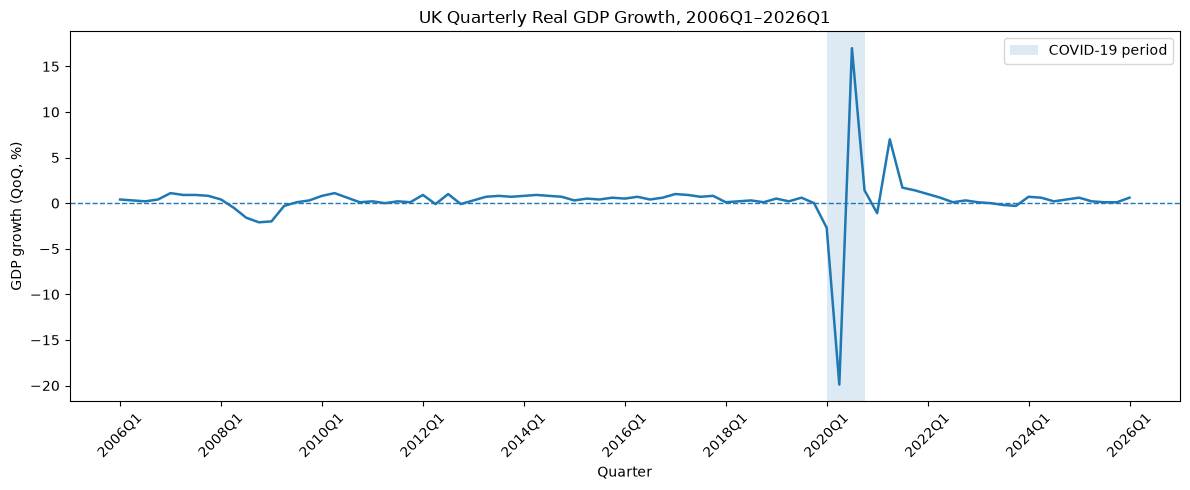

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    model_dataset["quarter"].astype(str),
    model_dataset["gdp_qoq"],
    linewidth=1.8
)

ax.axhline(
    y=0,
    linewidth=1,
    linestyle="--"
)

ax.axvspan(
    "2020Q1",
    "2020Q4",
    alpha=0.15,
    label="COVID-19 period"
)

ax.set_title("UK Quarterly Real GDP Growth, 2006Q1–2026Q1")
ax.set_xlabel("Quarter")
ax.set_ylabel("GDP growth (QoQ, %)")

ax.set_xticks(range(0, len(model_dataset), 8))
ax.set_xticklabels(
    model_dataset["quarter"].astype(str).iloc[::8],
    rotation=45
)

ax.legend()
plt.tight_layout()
plt.savefig(
    "../figures/01_gdp_growth.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Quarterly UK GDP growth is relatively stable over most of the sample, but the series contains several large macroeconomic shocks. The Global Financial Crisis is visible in 2008–2009, while the COVID-19 period produces by far the largest contraction and rebound in the dataset.

## 3. Macroeconomic Predictor Dynamics

The M3 information set is used to summarise the time-series behaviour of the main macroeconomic predictors. This provides a compact view of activity, labour-market, inflation, monetary-policy and confidence dynamics over the sample.

In [9]:
m3_predictors = [
    "gdp_monthly_m3",
    "services_m3",
    "industrial_production_m3",
    "construction_m3",
    "retail_sales_m3",
    "unemployment_rate_m3",
    "vacancies_thousands_m3",
    "wage_growth_m3",
    "cpi_inflation_m3",
    "bank_rate_m3",
    "consumer_confidence_m3",
    "oecd_cli_m3"
]

In [10]:
print(model_dataset.shape)
print(model_dataset.columns.tolist())

(81, 38)
['quarter', 'gdp_qoq', 'gdp_monthly_m1', 'gdp_monthly_m2', 'gdp_monthly_m3', 'services_m1', 'services_m2', 'services_m3', 'industrial_production_m1', 'industrial_production_m2', 'industrial_production_m3', 'construction_m1', 'construction_m2', 'construction_m3', 'retail_sales_m1', 'retail_sales_m2', 'retail_sales_m3', 'unemployment_rate_m1', 'unemployment_rate_m2', 'unemployment_rate_m3', 'vacancies_thousands_m1', 'vacancies_thousands_m2', 'vacancies_thousands_m3', 'wage_growth_m1', 'wage_growth_m2', 'wage_growth_m3', 'cpi_inflation_m1', 'cpi_inflation_m2', 'cpi_inflation_m3', 'bank_rate_m1', 'bank_rate_m2', 'bank_rate_m3', 'consumer_confidence_m1', 'consumer_confidence_m2', 'consumer_confidence_m3', 'oecd_cli_m1', 'oecd_cli_m2', 'oecd_cli_m3']


In [11]:
model_dataset[m3_predictors].head()

,gdp_monthly_m3,services_m3,industrial_production_m3,construction_m3,retail_sales_m3,unemployment_rate_m3,vacancies_thousands_m3,wage_growth_m3,cpi_inflation_m3,bank_rate_m3,consumer_confidence_m3,oecd_cli_m3
0,0.4,0.2,1.2,0.2,0.8,5.3,598.0,4.9,1.8,4.50,-7.0,100.8848
1,0.2,0.1,0.6,-0.2,0.5,5.5,608.0,4.9,2.5,4.50,-4.0,101.3334
2,0.3,0.3,0.2,0.3,-0.4,5.5,618.0,4.1,2.4,4.75,-7.0,101.8751
3,0.9,1.2,-0.3,0.2,0.7,5.5,618.0,4.9,3.0,5.00,-8.0,102.5540
4,0.2,0.4,-0.2,-0.2,0.3,5.5,647.0,5.8,3.1,5.25,-8.0,103.1211


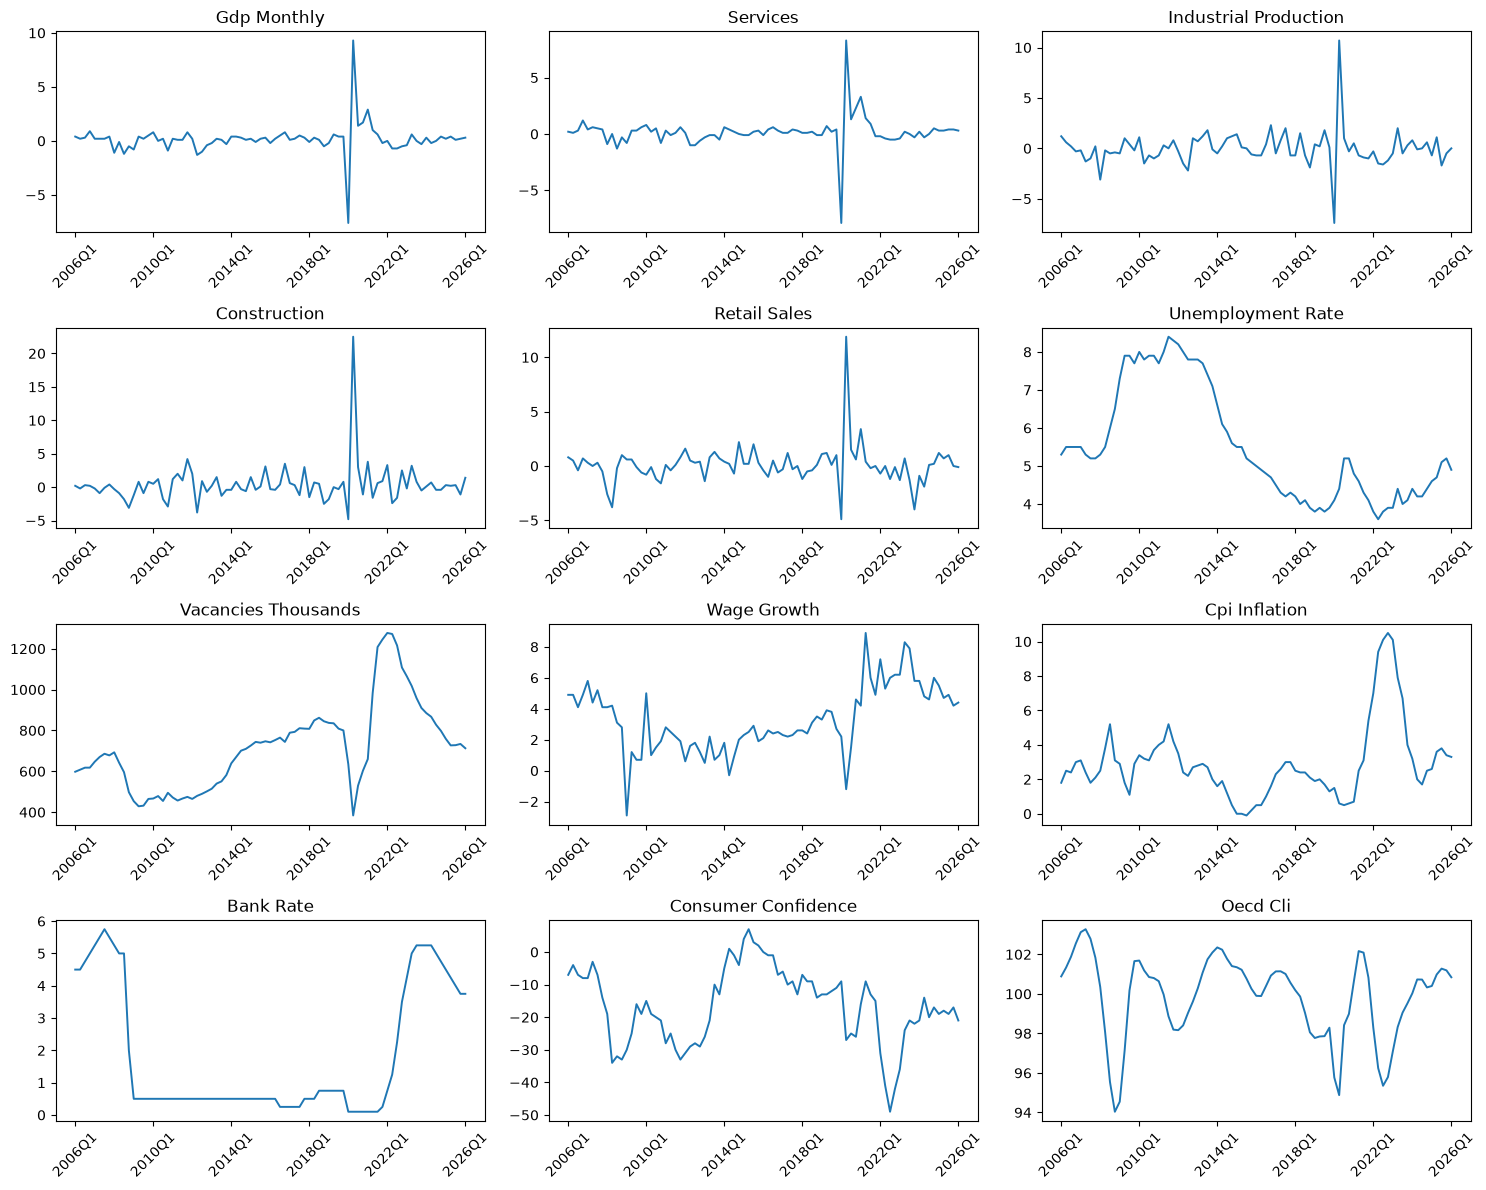

In [12]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(15, 12)
)

axes = axes.flatten()

for ax, predictor in zip(axes, m3_predictors):

    ax.plot(
        model_dataset["quarter"].astype(str),
        model_dataset[predictor],
        linewidth=1.4
    )

    ax.set_title(predictor.replace("_m3", "").replace("_", " ").title())

    ax.set_xticks(range(0, len(model_dataset), 16))
    ax.set_xticklabels(
        model_dataset["quarter"].astype(str).iloc[::16],
        rotation=45
    )

plt.tight_layout()
plt.savefig(
    "../figures/02_m3_predictor_dynamics.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The M3 predictors capture several distinct macroeconomic episodes across the sample. Activity indicators show particularly large movements during the COVID-19 shock and subsequent reopening, while the labour-market series display slower-moving cyclical dynamics. The post-2021 period is characterised by a sharp rise in inflation and Bank Rate, alongside substantial movements in consumer confidence.

## 4. Correlation Structure

Pairwise correlations are examined using the M3 information set, which provides the most complete within-quarter information. The analysis describes contemporaneous relationships between GDP growth and the predictors; correlations are not interpreted as measures of causal or predictive importance.

In [13]:


correlation_variables = ["gdp_qoq"] + m3_predictors

correlation_matrix = model_dataset[correlation_variables].corr()


In [14]:
model_dataset[
    ["quarter", "gdp_qoq", "gdp_monthly_m1", "gdp_monthly_m2", "gdp_monthly_m3"]
].loc[model_dataset["quarter"].between("2019Q1", "2021Q4")]

,quarter,gdp_qoq,gdp_monthly_m1,gdp_monthly_m2,gdp_monthly_m3
52,2019Q1,0.5,0.5,0.6,-0.2
53,2019Q2,0.2,-0.4,0.5,0.6
54,2019Q3,0.6,0.1,-0.2,0.4
55,2019Q4,0.0,-0.1,-0.3,0.4
56,2020Q1,-2.7,-0.1,0.0,-7.6
57,2020Q2,-19.9,-19.2,2.1,9.3
58,2020Q3,17.0,6.7,3.5,1.4
59,2020Q4,1.4,0.3,-2.1,1.7
60,2021Q1,-1.1,-3.2,1.2,2.9
61,2021Q2,7.0,3.2,1.4,1.0


In [15]:
model_dataset.loc[
    ~model_dataset["quarter"].between("2020Q1", "2021Q4"),
    ["gdp_qoq", "gdp_monthly_m3"]
].corr()

,gdp_qoq,gdp_monthly_m3
gdp_qoq,1.00000,0.39243
gdp_monthly_m3,0.39243,1.00000


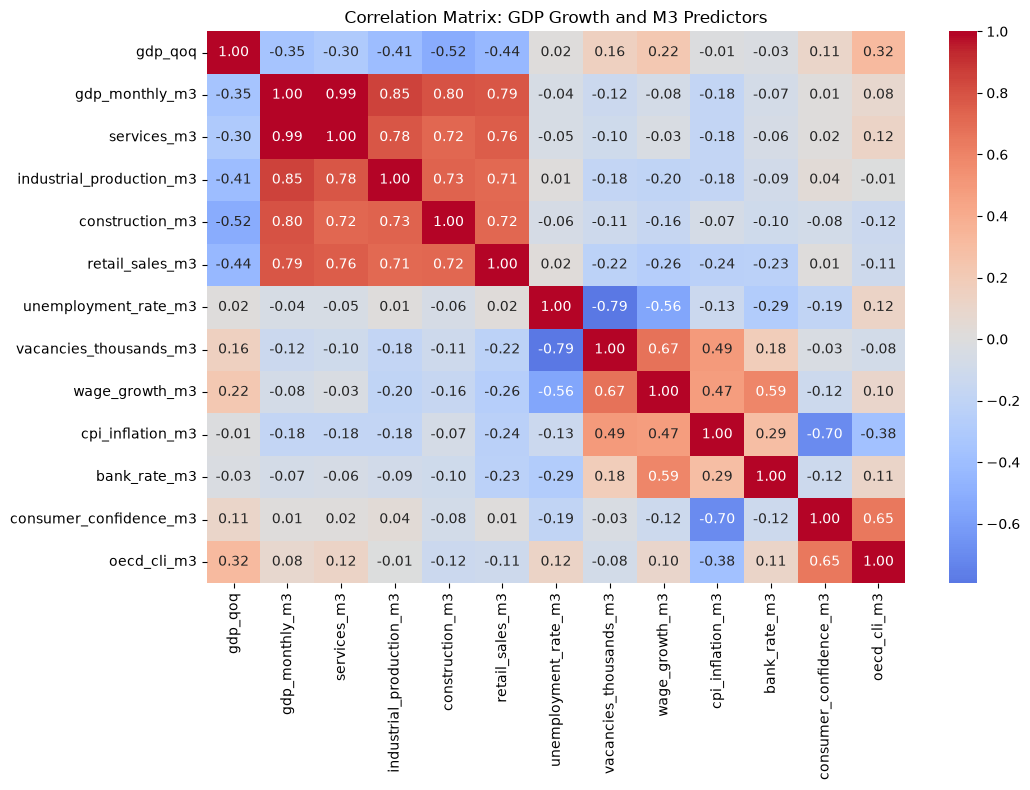

In [16]:
fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set_title("Correlation Matrix: GDP Growth and M3 Predictors")

plt.tight_layout()
plt.savefig(
    "../figures/03_m3_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [17]:
gdp_correlations = (
    correlation_matrix["gdp_qoq"]
    .drop("gdp_qoq")
    .sort_values(key=abs, ascending=False)
)

gdp_correlations

construction_m3            -0.518961
retail_sales_m3            -0.439168
industrial_production_m3   -0.414910
gdp_monthly_m3             -0.353830
oecd_cli_m3                 0.315383
services_m3                -0.299768
wage_growth_m3              0.218325
vacancies_thousands_m3      0.155677
consumer_confidence_m3      0.105989
bank_rate_m3               -0.027134
unemployment_rate_m3        0.016919
cpi_inflation_m3           -0.008930
Name: gdp_qoq, dtype: float64

The M3 correlation structure reveals strong co-movement among the main activity indicators, particularly monthly GDP, services, industrial production, construction and retail sales. Labour-market indicators also display economically intuitive relationships, including a strong negative correlation between unemployment and vacancies.

Full-sample correlations between quarterly GDP growth and several activity indicators are strongly affected by the exceptional dynamics of the COVID-19 period. For example, the correlation between quarterly GDP growth and the M3 monthly GDP indicator changes from -0.35 in the full sample to approximately 0.39 when 2020Q1–2021Q4 is excluded. These correlations are therefore treated as descriptive relationships rather than measures of predictive importance or criteria for feature selection.

## 5. Economic Shocks and Extreme Observations

The sample contains several unusually large GDP movements associated with genuine macroeconomic shocks, most notably the Global Financial Crisis and the COVID-19 pandemic. The pandemic observations are particularly extreme relative to the rest of the sample and materially affect some full-sample descriptive statistics and correlations.

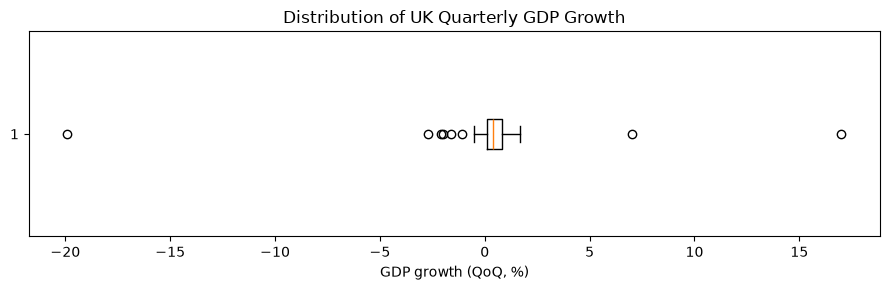

In [18]:
fig, ax = plt.subplots(figsize=(9, 3))

ax.boxplot(
    model_dataset["gdp_qoq"],
    orientation="horizontal"
)

ax.set_title("Distribution of UK Quarterly GDP Growth")
ax.set_xlabel("GDP growth (QoQ, %)")

plt.tight_layout()
plt.savefig(
    "../figures/04_gdp_growth_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The distribution confirms that the COVID-19 contraction and rebound are extreme relative to typical quarterly GDP movements.

## 6. Nowcasting Information Sets

The M1, M2 and M3 datasets represent progressively expanding information sets within each quarter, reflecting indicator-specific publication lags.

In [19]:
dataset_m1 = pd.read_csv("../data/processed/dataset_m1.csv")
dataset_m2 = pd.read_csv("../data/processed/dataset_m2.csv")
dataset_m3 = pd.read_csv("../data/processed/dataset_m3.csv")

print("M1:", dataset_m1.shape)
print("M2:", dataset_m2.shape)
print("M3:", dataset_m3.shape)

M1: (81, 4)
M2: (81, 8)
M3: (81, 20)


In [20]:
print("M1 columns:")
print(dataset_m1.columns.tolist())

print("\nM2 columns:")
print(dataset_m2.columns.tolist())

print("\nM3 columns:")
print(dataset_m3.columns.tolist())

M1 columns:
['quarter', 'gdp_qoq', 'bank_rate_m1', 'consumer_confidence_m1']

M2 columns:
['quarter', 'gdp_qoq', 'bank_rate_m1', 'bank_rate_m2', 'consumer_confidence_m1', 'consumer_confidence_m2', 'cpi_inflation_m1', 'retail_sales_m1']

M3 columns:
['quarter', 'gdp_qoq', 'bank_rate_m1', 'bank_rate_m2', 'bank_rate_m3', 'consumer_confidence_m1', 'consumer_confidence_m2', 'consumer_confidence_m3', 'cpi_inflation_m1', 'cpi_inflation_m2', 'retail_sales_m1', 'retail_sales_m2', 'oecd_cli_m1', 'gdp_monthly_m1', 'services_m1', 'industrial_production_m1', 'construction_m1', 'unemployment_rate_m1', 'vacancies_thousands_m1', 'wage_growth_m1']


In [21]:
availability = pd.DataFrame({
    "Information set": ["M1", "M2", "M3"],
    "Available features": [
        dataset_m1.shape[1] - 2,
        dataset_m2.shape[1] - 2,
        dataset_m3.shape[1] - 2
    ]
})

availability

,Information set,Available features
0,M1,2
1,M2,6
2,M3,18


The number of available features increases substantially from M1 to M3, reflecting the ragged-edge structure created by indicator-specific publication lags. Early-quarter nowcasts therefore rely on limited contemporaneous information, while later information sets incorporate progressively more observations as new data are released.

## 7. EDA Summary

The exploratory analysis shows substantial variation in UK GDP growth and its macroeconomic predictors, with the COVID-19 shock representing the most extreme episode. Strong co-movement among activity indicators also suggests considerable overlap in the information they contain.

Full-sample correlations are sensitive to extreme macroeconomic episodes and are therefore interpreted descriptively rather than used for feature selection. These observations are retained as genuine economic events.

Finally, the expanding M1–M3 information sets capture the ragged-edge nature of nowcasting, with progressively more information becoming available throughout the quarter. This provides the basis for evaluating model performance across different information sets.